# 02 — Flashbots Exploratory Data Analysis

**Purpose:** describe the arrival process and the gas-related variables of the two audited days, to decide what
can be forecast and how.

**What is computed here:**
- Everything below is recomputed from the row-complete extract (`Flashbots/data/derived/tx_extract_<date>.npz`)
  and the 1-s series (`Flashbots/time_series/target_series_<date>_1s.csv.gz`).
- The key numbers are checked against the stored `Flashbots/eda/eda_summary.json` written by `run_eda.py`.

**Descriptive only.** No model is fitted. Two isolated days (3 weeks apart) **cannot** establish daily or weekly
seasonality, trend or day-of-week effects.

## Setup

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd()
while not (ROOT / "Flashbots" / "fbcommon.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FB = ROOT / "Flashbots"
for sub in ("", "forecasting", "evaluation", "time_series", "data_audit", "preprocessing"):
    sys.path.insert(0, str(FB / sub))

import numpy as np
import pandas as pd
import fbcommon as fc
fc.plot_style()
%matplotlib inline
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 1e4 else f"{v:.4g}")
print("repository:", ROOT)
print({k: v for k, v in fc.environment().items() if k != "platform"})

repository: C:\OJT_SEM3\AI-Assisted-Permissioned-Blockchain-Architecture-


{'python': '3.14.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit_learn': '1.9.1', 'matplotlib': '3.11.2', 'pyyaml': '6.0.3'}


In [2]:
from scipy import signal, stats
series = {d: fc.load_target_series(d) for d in fc.DATES}
tx = {d: fc.load_extract(d) for d in fc.DATES}
counts = {d: series[d]["arrival_count"].to_numpy(float) for d in fc.DATES}
STORED = json.loads((FB / "eda" / "eda_summary.json").read_text(encoding="utf-8"))
COL = fc.DAY_COLOR

## 1. Arrival-rate overview

In [3]:
overview = pd.DataFrame({d: {"transactions": int(c.sum()), "mean tx/s": c.mean(), "sd (1 s)": c.std(ddof=1),
                             "median (1 s)": np.median(c), "p95 (1 s)": np.quantile(c, .95), "p99 (1 s)": np.quantile(c, .99),
                             "max (1 s)": c.max(), "zero seconds": int((c == 0).sum())} for d, c in counts.items()})
display(overview)
for d in fc.DATES:
    assert np.isclose(overview.loc["mean tx/s", d], STORED["days"][d]["mean_tx_per_s"])

,2026-09-21,2026-10-12
transactions,"1,055,934","913,856"
mean tx/s,12.22,10.58
sd (1 s),7.479,8.454
median (1 s),11,9
p95 (1 s),24,21
p99 (1 s),35,30
max (1 s),362,817
zero seconds,41,83


## 2. Transaction activity over time

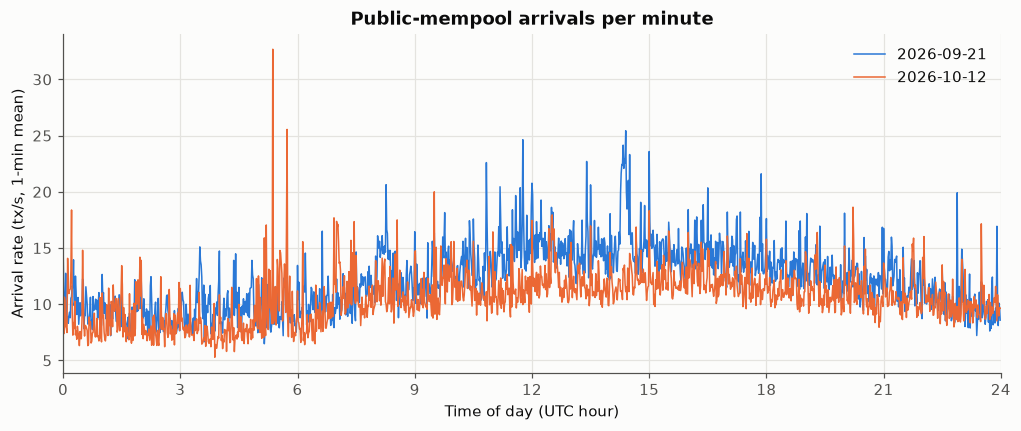

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
for d in fc.DATES:
    ax.plot(np.arange(1440) / 60, counts[d].reshape(-1, 60).mean(1), color=COL[d], lw=1, label=d)
ax.set(xlim=(0, 24), xticks=range(0, 25, 3), xlabel="Time of day (UTC hour)", ylabel="Arrival rate (tx/s, 1-min mean)",
       title="Public-mempool arrivals per minute")
ax.legend(); plt.show()

Both days hover around 10-15 tx/s with short spikes. 12 Oct has two isolated bursts at about 05:20 and 05:45 UTC.
These bursts dominate the forecasting errors later.

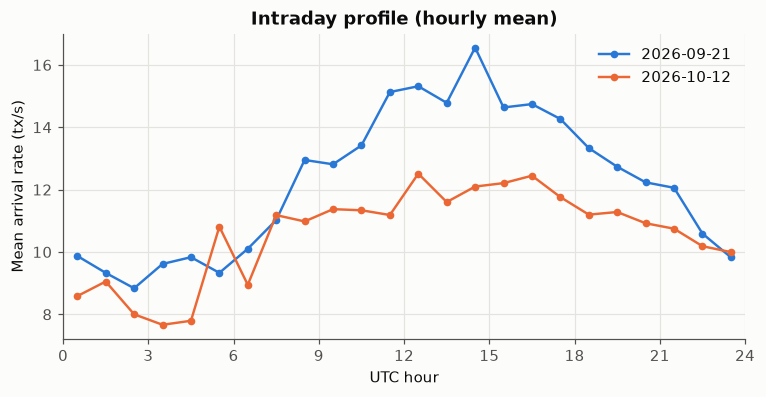

peak/trough ratio: {'2026-09-21': 1.87, '2026-10-12': 1.63} | trough hour: {'2026-09-21': 2, '2026-10-12': 3} | peak hour: {'2026-09-21': 14, '2026-10-12': 12}


In [5]:
hourly = pd.DataFrame({d: counts[d].reshape(24, 3600).mean(1) for d in fc.DATES})
fig, ax = plt.subplots(figsize=(8, 3.6))
for d in fc.DATES:
    ax.plot(hourly.index + .5, hourly[d], marker="o", ms=4, color=COL[d], label=d)
ax.set(xlim=(0, 24), xticks=range(0, 25, 3), xlabel="UTC hour", ylabel="Mean arrival rate (tx/s)", title="Intraday profile (hourly mean)")
ax.legend(); plt.show()
print("peak/trough ratio:", (hourly.max() / hourly.min()).round(2).to_dict(), "| trough hour:", hourly.idxmin().to_dict(), "| peak hour:", hourly.idxmax().to_dict())

Both days are lowest overnight (02-05 UTC) and highest around midday (12-14 UTC). This is *consistent with* a
daily cycle, but two days cannot establish one. The forecasting stage therefore does not assume daily seasonality,
and tests a "same time on the other date" profile only as an exploratory comparator.

## 3. Burstiness: is this a Poisson process?

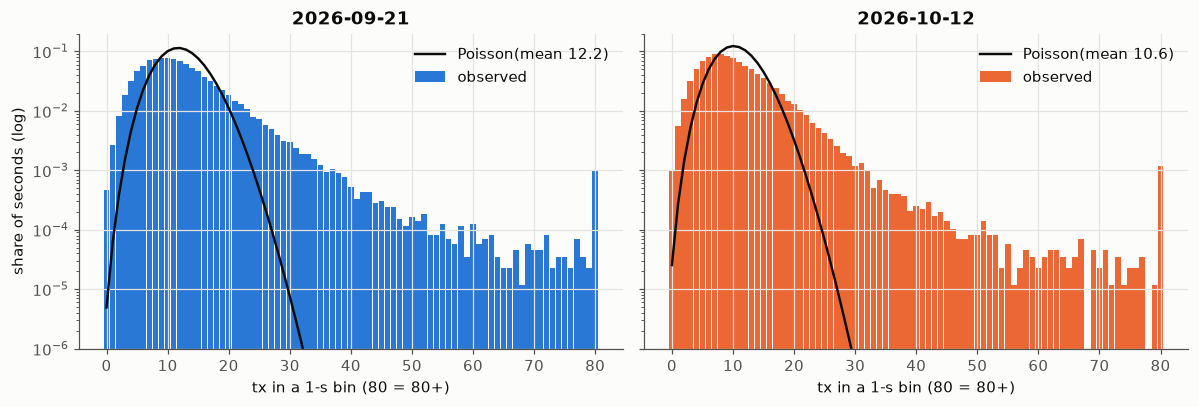

date,2026-09-21,2026-10-12
window_s,,
1,4.576,6.758
5,9.017,11.75
10,12.32,14.73
60,41.38,30.74
300,157.9,95.21
900,432,225.7
3600,1589,742.4


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, d in zip(axes, fc.DATES):
    c = counts[d].astype(int); k = np.arange(81)
    ax.bar(k, np.bincount(np.minimum(c, 80), minlength=81) / len(c), color=COL[d], width=.9, label="observed")
    ax.plot(k, stats.poisson.pmf(k, c.mean()), color=fc.TEXT, label=f"Poisson(mean {c.mean():.1f})")
    ax.set(yscale="log", ylim=(1e-6, .2), xlabel="tx in a 1-s bin (80 = 80+)", title=d); ax.legend()
axes[0].set_ylabel("share of seconds (log)"); plt.tight_layout(); plt.show()

rows = []
for d in fc.DATES:
    for w in (1, 5, 10, 60, 300, 900, 3600):
        agg = counts[d].reshape(-1, w).sum(1)
        rows.append({"date": d, "window_s": w, "variance/mean": agg.var(ddof=1) / agg.mean()})
disp = pd.DataFrame(rows).pivot(index="window_s", columns="date", values="variance/mean")
disp

- **Heavy tail.** 1-s counts have a far heavier right tail than a Poisson process with the same mean.
- **Over-dispersion.** The variance/mean ratio, which is 1 for Poisson, grows from about 5 at 1 s to about 1,000
  at 1 h. Arrivals are **clustered at every timescale**.
- **Consequence for Fabric workload generation.** A Poisson generator at the mean rate would badly understate
  burstiness. Replaying the observed timing (or rate) keeps it.

## 4. Inter-arrival gaps

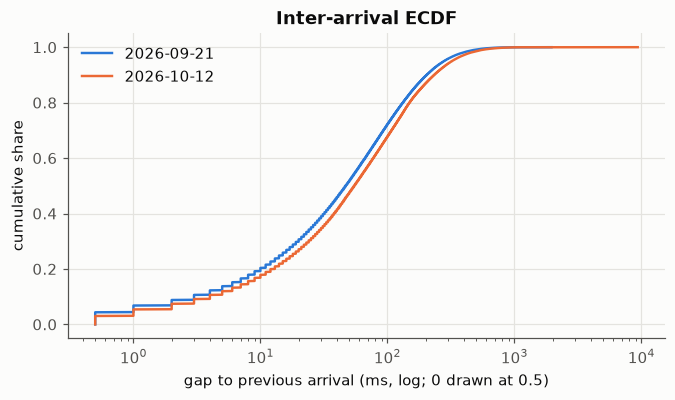

,date,median_ms,p95_ms,share_zero_gap,max_ms
0,2026-09-21,47,280,0.04375,1961
1,2026-10-12,55,323,0.03042,9363


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
rows = []
for d in fc.DATES:
    g = np.diff(tx[d]["timestamp_ms"]).astype(float)
    xs = np.sort(g); idx = np.unique(np.linspace(0, len(xs) - 1, 3000).astype(int))
    ax.plot(np.maximum(xs[idx], .5), (idx + 1) / len(xs), color=COL[d], label=d)
    rows.append({"date": d, "median_ms": np.median(g), "p95_ms": np.quantile(g, .95), "share_zero_gap": (g == 0).mean(), "max_ms": g.max()})
ax.set(xscale="log", xlabel="gap to previous arrival (ms, log; 0 drawn at 0.5)", ylabel="cumulative share", title="Inter-arrival ECDF")
ax.legend(); plt.show()
pd.DataFrame(rows)

## 5. Temporal dependence: persistence and the 12-second Ethereum slot

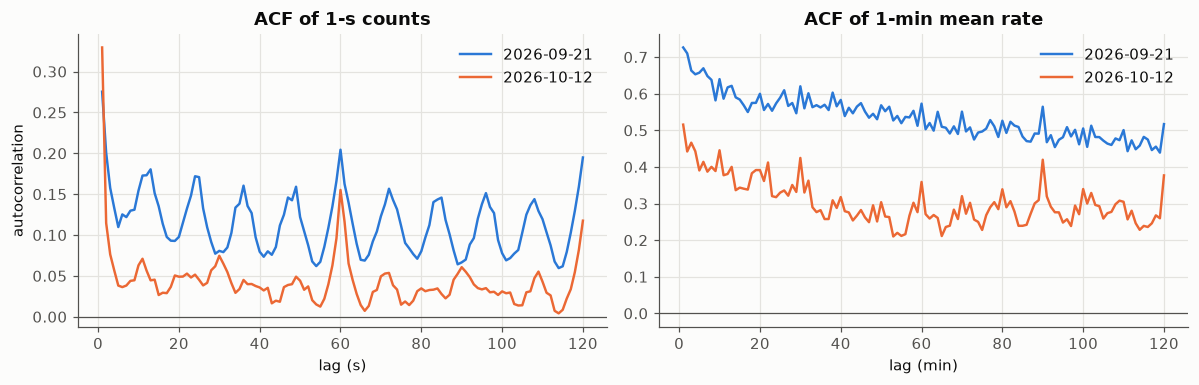

2026-09-21: strongest period between 5 and 60 s = 12.00 s; 1-min ACF lag 1 = 0.73
2026-10-12: strongest period between 5 and 60 s = 12.00 s; 1-min ACF lag 1 = 0.52


In [8]:
def acf(x, lags):
    x = x - x.mean(); den = x @ x
    return np.array([x[:-k] @ x[k:] / den for k in range(1, lags + 1)])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for d in fc.DATES:
    axes[0].plot(range(1, 121), acf(counts[d], 120), color=COL[d], label=d)
    axes[1].plot(range(1, 121), acf(counts[d].reshape(-1, 60).mean(1), 120), color=COL[d], label=d)
axes[0].set(xlabel="lag (s)", ylabel="autocorrelation", title="ACF of 1-s counts")
axes[1].set(xlabel="lag (min)", title="ACF of 1-min mean rate")
for ax in axes: ax.axhline(0, color=fc.TEXT2, lw=.8); ax.legend()
plt.tight_layout(); plt.show()

for d in fc.DATES:
    f, p = signal.periodogram(counts[d] - counts[d].mean(), fs=1.0)
    band = (f >= 1 / 60) & (f <= 1 / 5)
    period = 1 / f[band][p[band].argmax()]
    print(f"{d}: strongest period between 5 and 60 s = {period:.2f} s; 1-min ACF lag 1 = {acf(counts[d].reshape(-1, 60).mean(1), 1)[0]:.2f}")
    assert abs(period - STORED["days"][d]["periodicity_12s"]["periodogram_peak_period_s_5_to_60"]) < 1e-9

- **Persistence.** The 1-minute rate is strongly autocorrelated: 0.73 / 0.52 at lag 1, still 0.57 / 0.36 after
  an hour. The recent level predicts the near future, and this is what level-tracking forecasters (EWMA, rolling
  means) exploit.
- **12-s cycle.** 1-s counts peak every 12 s; the periodogram maximum is exactly 12.0 s on both days. This matches
  Ethereum's 12-s slot time. It motivates a seasonal-naive-12 baseline in the forecasting stage.
- **Other peaks.** At 60 s and at 10 / 30 / 60 / 90 min. Scheduled bot activity is a **hypothesis**, not tested.

## 6. Gas-related variables

date,2026-09-21,2026-10-12
fee cap median (gwei),1.143,0.5162
fee cap p99 (gwei),501.9,200
tip cap median (gwei),0.2393,0.2
gas limit median,"69,736","77,395"
gas limit p99,"5,000,000","3,000,000"
calldata median (B),68,68
no calldata share,0.3651,0.3986
contract creation share,0.0003883,0.0008108


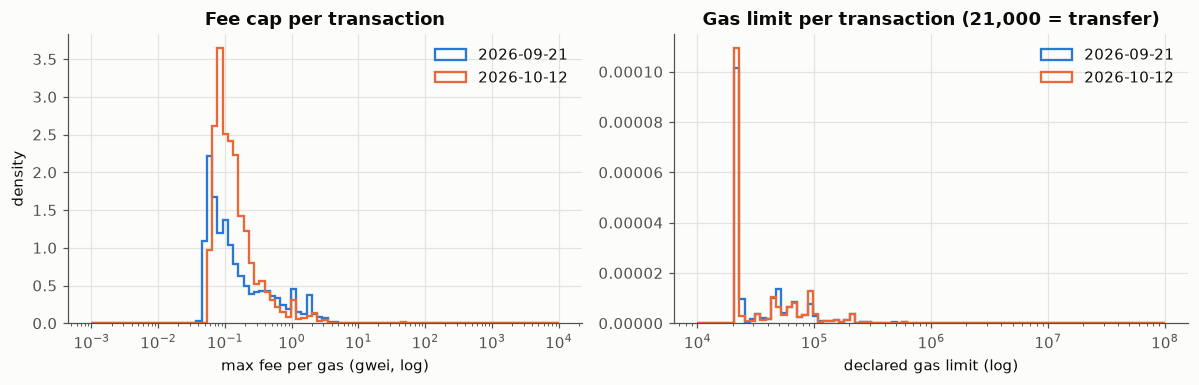

,2026-09-21,2026-10-12
0 legacy,0.1563,0.192
1 access-list,0.006566,9.958e-05
2 EIP-1559,0.8265,0.7936
4 EIP-7702,0.01066,0.01434


In [9]:
rows = []
for d in fc.DATES:
    t = tx[d]
    rows.append({"date": d, "fee cap median (gwei)": np.median(t["gas_fee_cap_gwei"]), "fee cap p99 (gwei)": np.quantile(t["gas_fee_cap_gwei"], .99),
                 "tip cap median (gwei)": np.median(t["gas_tip_cap_gwei"]), "gas limit median": np.median(t["gas"]),
                 "gas limit p99": np.quantile(t["gas"], .99), "calldata median (B)": np.median(t["data_size"]),
                 "no calldata share": (t["data_size"] == 0).mean(), "contract creation share": t["to_is_null"].mean()})
display(pd.DataFrame(rows).set_index("date").T)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for d in fc.DATES:
    axes[0].hist(np.clip(tx[d]["gas_fee_cap_gwei"], 1e-3, 1e4), bins=np.logspace(-3, 4, 90), histtype="step", lw=1.5, density=True, color=COL[d], label=d)
    axes[1].hist(tx[d]["gas"], bins=np.logspace(4, 8, 90), histtype="step", lw=1.5, density=True, color=COL[d], label=d)
axes[0].set(xscale="log", xlabel="max fee per gas (gwei, log)", ylabel="density", title="Fee cap per transaction")
axes[1].set(xscale="log", xlabel="declared gas limit (log)", title="Gas limit per transaction (21,000 = transfer)")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

types = pd.DataFrame({d: pd.Series(tx[d]["tx_type"]).value_counts(normalize=True).sort_index() for d in fc.DATES})
types.index = types.index.map({0: "0 legacy", 1: "1 access-list", 2: "2 EIP-1559", 3: "3 blob", 4: "4 EIP-7702"})
types

## 7. Gas demand vs arrival rate (a candidate secondary target)

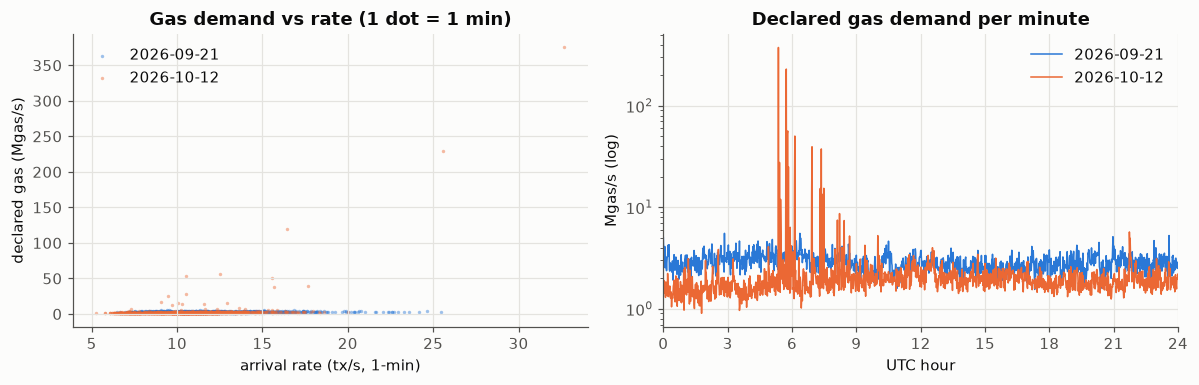

,date,mean Mgas/s,"Spearman(rate, gas) per minute",share of daily gas in busiest 0.1% of seconds
0,2026-09-21,2.854,-0.05242,0.01529
1,2026-10-12,2.686,0.5729,0.2939


In [10]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for d in fc.DATES:
    gas = series[d]["gas_limit_sum"].to_numpy(float)
    rate_m, gas_m = counts[d].reshape(-1, 60).mean(1), gas.reshape(-1, 60).mean(1) / 1e6
    axes[0].scatter(rate_m, gas_m, s=5, alpha=.45, color=COL[d], label=d, linewidths=0)
    axes[1].plot(np.arange(1440) / 60, gas_m, color=COL[d], lw=1, label=d)
    top = np.sort(gas)[::-1][: int(fc.DAY_S * .001)].sum() / gas.sum()
    rows.append({"date": d, "mean Mgas/s": gas.mean() / 1e6, "Spearman(rate, gas) per minute": stats.spearmanr(rate_m, gas_m).statistic,
                 "share of daily gas in busiest 0.1% of seconds": top})
axes[0].set(xlabel="arrival rate (tx/s, 1-min)", ylabel="declared gas (Mgas/s)", title="Gas demand vs rate (1 dot = 1 min)")
axes[1].set(yscale="log", xlim=(0, 24), xticks=range(0, 25, 3), xlabel="UTC hour", ylabel="Mgas/s (log)", title="Declared gas demand per minute")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows)

- **Weak and unstable link to the rate.** Declared gas demand relates to the arrival rate inconsistently:
  Spearman -0.05 on 21 Sep and 0.57 on 12 Oct.
- **Rare bursts dominate.** On 12 Oct, 29% of the day's declared gas falls in its busiest 0.1% of seconds (1.5% on
  21 Sep), driven by rare large-gas-limit transactions.
- **Expectation.** This target should be much harder to forecast than the arrival rate, and it is not a Fabric
  quantity (Fabric has no gas).

## 8. Distribution shift between the two dates

In [11]:
shift = pd.read_csv(FB / "eda" / "distribution_shift.csv")
shift[["quantity", "median_2026-09-21", "median_2026-10-12", "mean_2026-09-21", "mean_2026-10-12", "ks_statistic"]]

,quantity,median_2026-09-21,median_2026-10-12,mean_2026-09-21,mean_2026-10-12,ks_statistic
0,per-minute mean arrival rate (tx/s),12.1,10.58,12.22,10.58,0.2993
1,1-s arrival count,11,9,12.22,10.58,0.1244
2,gas fee cap per tx (gwei),1.149,0.5134,28.31,21.73,0.2045
3,gas limit per tx,"69,736","77,872","235,205","253,094",0.05155
4,calldata bytes per tx,68,68,335.7,313.9,0.03348


The per-minute arrival rate shifted down by about 13% (KS D = 0.30), and the median fee cap halved. Read the KS
statistic as an effect size: the p-values assume independence, which autocorrelated series violate. This shift
makes 12 Oct a genuine out-of-sample test day for forecasting.

## EDA conclusions for the next stages

| Observation | Consequence |
|---|---|
| Strong persistence of the level | Level-tracking forecasters (EWMA, rolling means) should beat naive |
| Heavy bursts, over-dispersion | Bursts cannot be anticipated from the level; expect the largest errors there |
| 12-s slot cycle | Test a seasonal-naive-12 baseline for H < 12 s |
| Two isolated days, shifted levels | No daily seasonal model; chronological split with 12 Oct as the test day |
| Gas demand dominated by rare bursts, not a Fabric quantity | Secondary target only |

Next: `../time_series/03_flashbots_preprocessing_time_series.ipynb`.